# PA3 · Poucos rótulos para classificar fauna

Este notebook reúne as figuras e tabelas para apresentar. 

Os arquivos são lidos de `outputs/`

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

REPO_DIR = Path.cwd()

candidates = [REPO_DIR, *REPO_DIR.parents, REPO_DIR / "deep-learning-pa3"]
ROOT = next((path for path in candidates if (path / "outputs/curva_orcamento.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Ajuste REPO_DIR para a pasta do repositório que contém outputs/.")
OUTPUTS = ROOT / "outputs"
plt.rcParams.update({"figure.dpi": 110, "font.size": 11})
pd.options.display.float_format = "{:.4f}".format


def show_plot(filename, width=1050):
    display(Image(filename=str(OUTPUTS / filename), width=width))


def metrics_from_matrix(filename):
    matrix = pd.read_csv(OUTPUTS / filename, index_col=0).to_numpy(dtype=float)
    counts = matrix.sum(axis=0) + matrix.sum(axis=1)
    class_f1 = np.divide(2 * matrix.diagonal(), counts, out=np.zeros_like(counts), where=counts > 0)
    return {"F1 macro": class_f1.mean(), "Acurácia": matrix.diagonal().sum() / matrix.sum()}


## Dados e método

| Conjunto | Imagens | Papel |
|---|---:|---|
| Train | 6.505 | Imagens para treino e pseudo-rotulagem |
| Orçamentos 1 / 5 / 20 | 21 / 105 / 420 | Rótulos humanos, com quantidade fixa por classe |
| Val | 202 | Escolher época e comparar limiares |
| Test_public | 811 | Reportar as métricas |

BioCLIP compara cada foto com 21 prompts, como `a camera trap photo of the red fox.`, e grava classe e confiança em um CSV. Treinamos o aluno com as etiquetas humanas e os pseudo-rótulos aceitos. O piso supervisionado usa somente as etiquetas humanas.

**Configuração usada** — ResNet-18 com pesos ImageNet, backbone congelado e cabeça linear de 21 classes. Imagens 224 × 224 com normalização ImageNet, Adam a 0,001, lote 16, 20 épocas. O aluno e os modelos da curva salvam a melhor época em F1 macro no val. O piso original da Parte 0 salva a última época.

## Parte 0 · Quanto conseguimos usando só 105 rótulos?

Apresentar o F1 macro e a acurácia dos dois pisos. A tabela calcula as métricas a partir das matrizes de confusão salvas.

In [2]:
floor = pd.DataFrame({
    "CNN do zero": metrics_from_matrix("cnn_test_public_confusion_matrix.csv"),
    "ResNet-18 ImageNet": metrics_from_matrix("resnet_test_public_confusion_matrix.csv"),
}).T
display(floor)


,F1 macro,Acurácia
CNN do zero,0.2395,0.2429
ResNet-18 ImageNet,0.4264,0.4747


**Curva do piso ResNet-18** — Comparar a evolução do treino e do val e apontar os intervalos em que o F1 de treino cresce sem melhora correspondente de validação.

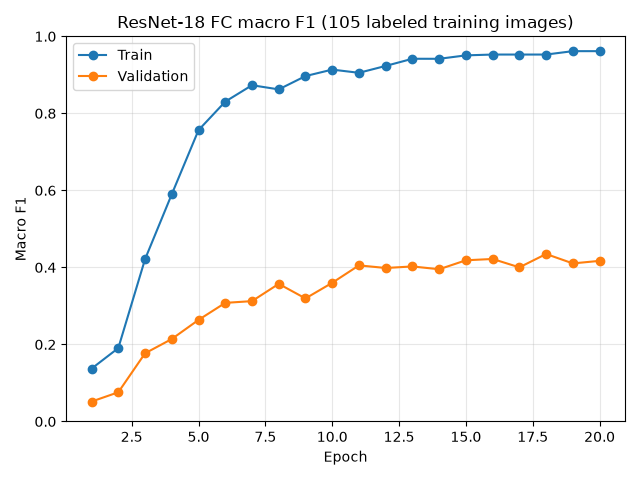

In [3]:
show_plot("resnet_training_validation_f1.png")

**Erros do piso** — Linhas representam classes reais e colunas representam classes previstas. Observar quais classes já eram difíceis antes da pseudo-rotulagem.

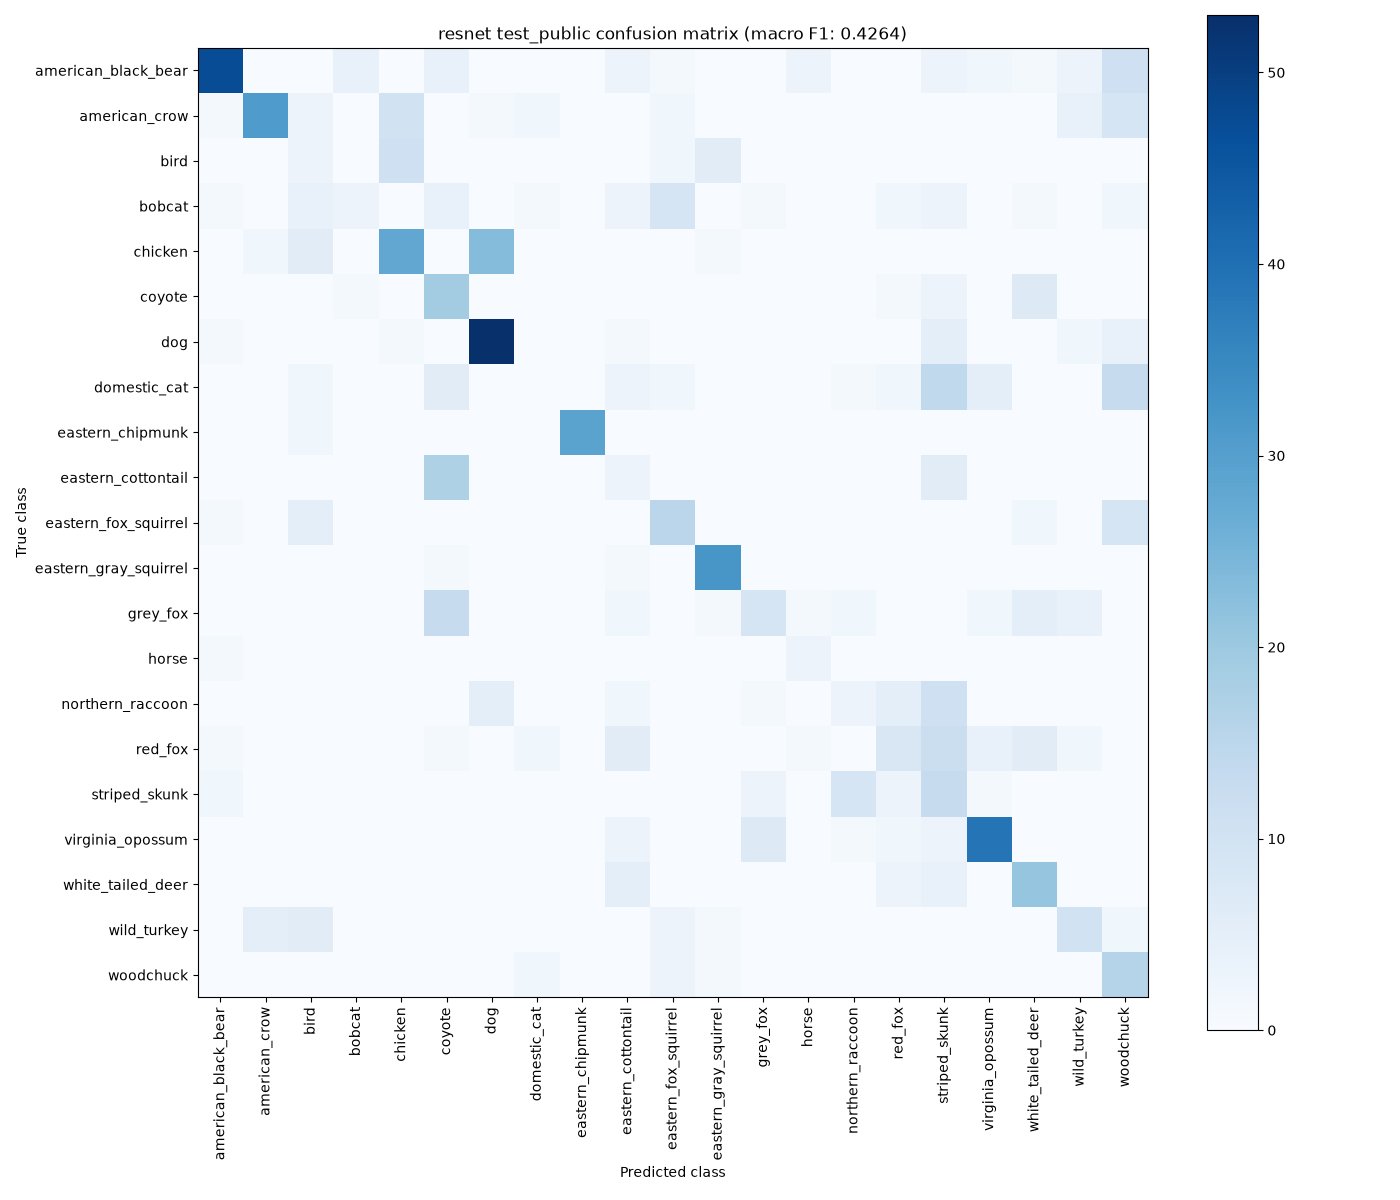

In [4]:
show_plot("resnet_test_public_confusion_matrix.png")

## Parte 1 · O professor e o ruído dos pseudo-rótulos

**BioCLIP zero-shot** — F1 macro 0,2637 e acurácia 0,3305. 
| Clase real | Predicción equivocada | Casos |
|---|---|---:|
| `eastern_chipmunk` | `domestic_cat` | 27 de 31 — 87,1% |
| `eastern_gray_squirrel` | `eastern_cottontail` | 22 de 34 — 64,7% |
| `eastern_cottontail` | `striped_skunk` | 15 de 26 — 57,7% |
| `coyote` | `red_fox` | 17 de 31 — 54,8% |
| `grey_fox` | `red_fox` | 15 de 39 — 38,5% |

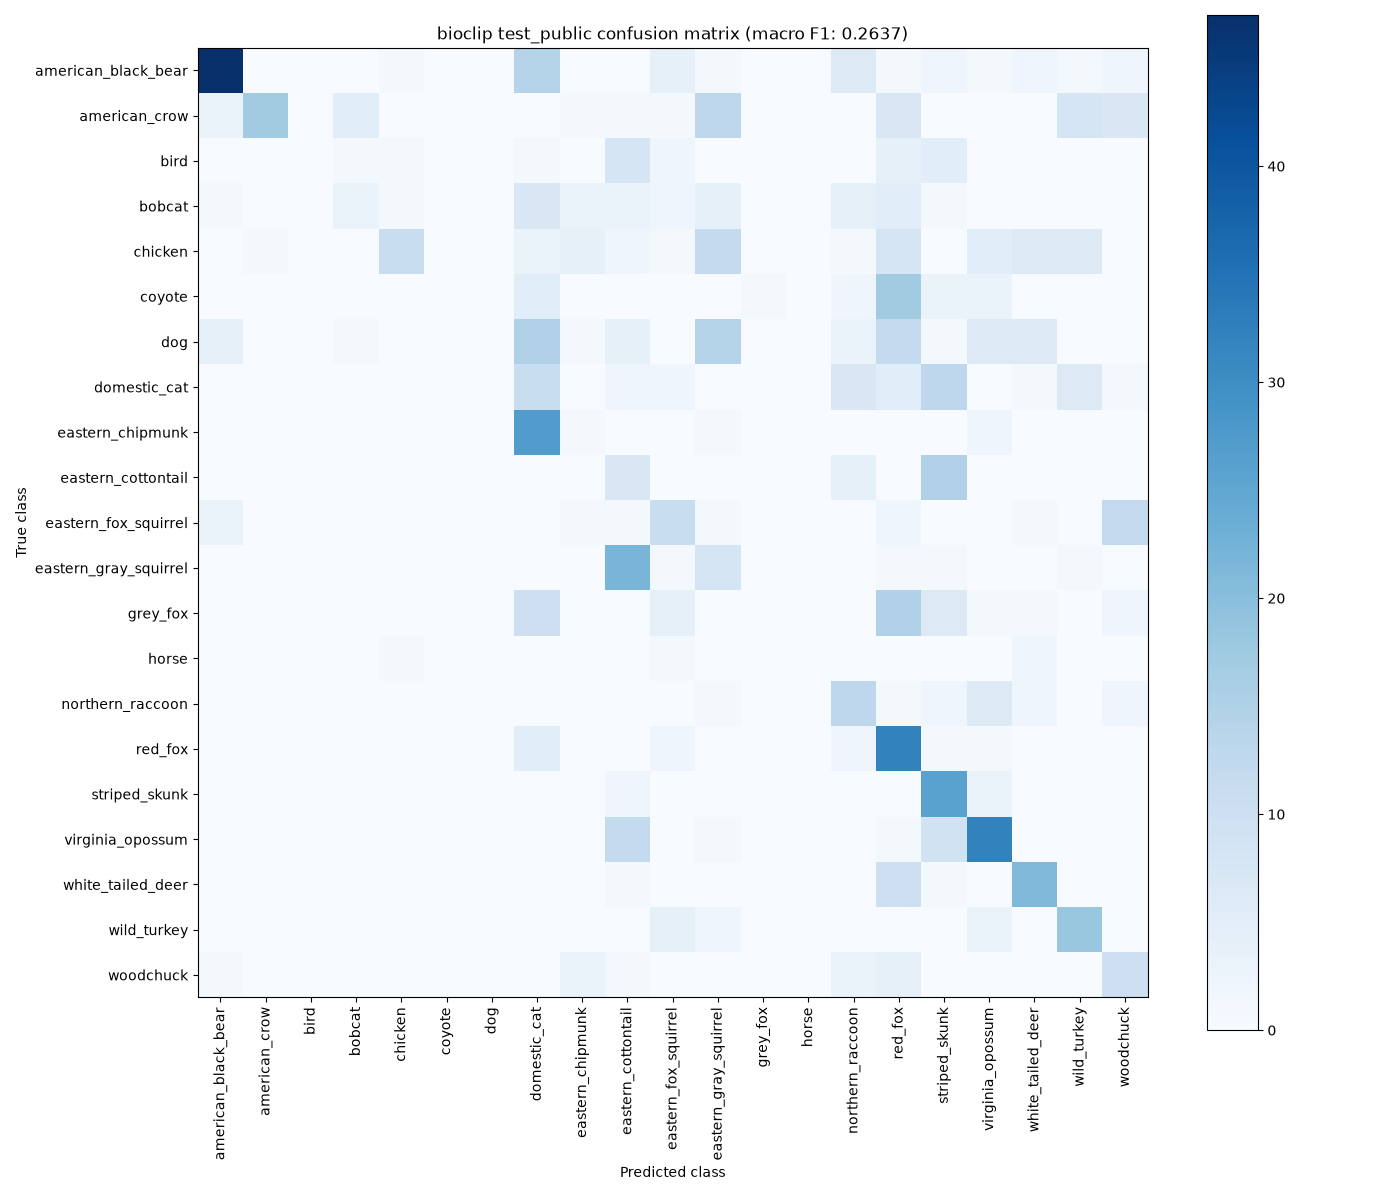

In [5]:
show_plot("bioclip_test_public_confusion_matrix.png")

### Como escolhemos o filtro?

Excluímos as 105 imagens com rótulo humano e inspecionamos a confiança das 6.400 restantes. O corte 0,8 foi exploratório. Depois propusemos cortes que retêm 75%, 50% e 25% dos candidatos e treinamos cada aluno com seed 42 por 20 épocas. A seleção usou o melhor F1 macro em **val**. Os valores de validação abaixo foram transcritos dos logs de treinamento, com quatro casas decimais.

In [6]:
thresholds = pd.DataFrame({
    "Limiar": [0.0, 0.49766308069229126, 0.7038832902908325, 0.8, 0.9445663690567017],
    "Pseudo-rótulos": [6400, 4800, 3200, 2594, 1600],
    "Retenção (%)": [100, 75, 50, 2594 / 6400 * 100, 25],
    "Melhor F1 no val": [np.nan, 0.2349, 0.2403, np.nan, 0.3555],
    "Melhor época": [pd.NA, 12, 2, pd.NA, 14],
})
display(thresholds.fillna("log indisponível"))


,Limiar,Pseudo-rótulos,Retenção (%),Melhor F1 no val,Melhor época
0,0.0000,6400,100.0000,log indisponível,log indisponível
1,0.4977,4800,75.0000,0.2349,12
2,0.7039,3200,50.0000,0.2403,2
3,0.8000,2594,40.5312,log indisponível,log indisponível
4,0.9446,1600,25.0000,0.3555,14


O corte **0,9445663690567017** teve o maior F1 de validação entre os três candidatos com logs disponíveis. Ele preservou 1.600 pseudo-rótulos, somados aos 105 humanos. Com esse corte, `bird`, `dog` e `horse` receberam zero pseudo-rótulos, mantendo seus cinco rótulos humanos por classe.

### A filtragem melhorou o aluno?

Comparar os quatro modelos em test_public. O CSV atual registra F1 0,4233 para o aluno filtrado. A corrida exploratória anterior com corte 0,8 obteve 0,3483. O arquivo atual não registra o caminho do checkpoint na tabela.

,F1 macro,Acurácia
Modelo,,
Piso supervisionado,0.4223,0.4686
Aluno sem filtro,0.2564,0.3280
Aluno filtrado,0.4233,0.4920
Professor BioCLIP,0.2637,0.3305


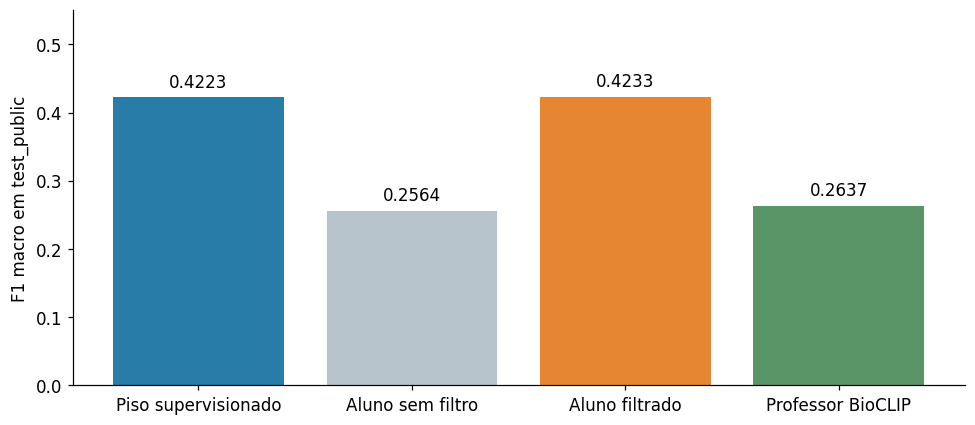

In [7]:
part1 = pd.read_csv(OUTPUTS / "trilha_c_test_public.csv")
names = {
    "baseline": "Piso supervisionado",
    "student_unfiltered": "Aluno sem filtro",
    "student_filtered": "Aluno filtrado",
    "bioclip": "Professor BioCLIP",
}
table = part1.assign(model=part1["model"].map(names)).rename(columns={
    "model": "Modelo", "macro_f1": "F1 macro", "accuracy": "Acurácia"
})
display(table.set_index("Modelo"))

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(table["Modelo"], table["F1 macro"], color=["#277da8", "#b8c4cc", "#e68632", "#5a9567"])
ax.bar_label(bars, fmt="%.4f", padding=4)
ax.set(ylabel="F1 macro em test_public", ylim=(0, 0.55))
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()


**O que dizer** — Aceitar todos os pseudo-rótulos piorou o resultado. A filtragem elevou o F1 macro do aluno de 0,2564 para 0,4233, próximo do piso de 0,4223 e acima do professor de 0,2637. Esta tabela corresponde a uma corrida por modelo.

### Em quais classes o aluno superou o professor?

Mostrar os maiores ganhos e perdas, usando os resultados por classe da avaliação atual.

In [8]:
per_class = pd.read_csv(OUTPUTS / "trilha_c_test_public_by_class.csv")
ranked = per_class.sort_values("delta_filtered_vs_bioclip", ascending=False)
selected = pd.concat([ranked.head(5), ranked.tail(3)])
display(selected[["class", "support", "bioclip", "student_filtered", "delta_filtered_vs_bioclip"]].set_index("class"))


,support,bioclip,student_filtered,delta_filtered_vs_bioclip
class,,,,
eastern_chipmunk,31,0.0444,0.9667,0.9222
eastern_gray_squirrel,34,0.1739,0.8421,0.6682
coyote,31,0.0000,0.5238,0.5238
eastern_cottontail,26,0.1522,0.5479,0.3958
dog,67,0.0000,0.3038,0.3038
bobcat,34,0.1364,0.0000,-0.1364
northern_raccoon,27,0.3611,0.2222,-0.1389
wild_turkey,27,0.5373,0.3008,-0.2366


O aluno recupera `eastern_chipmunk`, classe em que o piso já ia bem e o professor confundia com gato. O filtro é compatível com uma redução da propagação de erros, junto ao aprendizado com rótulos humanos. As métricas por classe permitem localizar os efeitos; a causa visual de cada erro precisa ser examinada nas imagens.

## Parte 2 · Quando os pseudo-rótulos ajudam mais?

Comparar piso e aluno com 1, 5 e 20 rótulos por classe. Com cinco rótulos, usar média e desvio-padrão amostral de três seeds (42, 43 e 44). Os outros dois orçamentos usam seed 42. A linha do professor é fixa porque seu zero-shot independe do orçamento humano. A referência do monitor é 0,686.

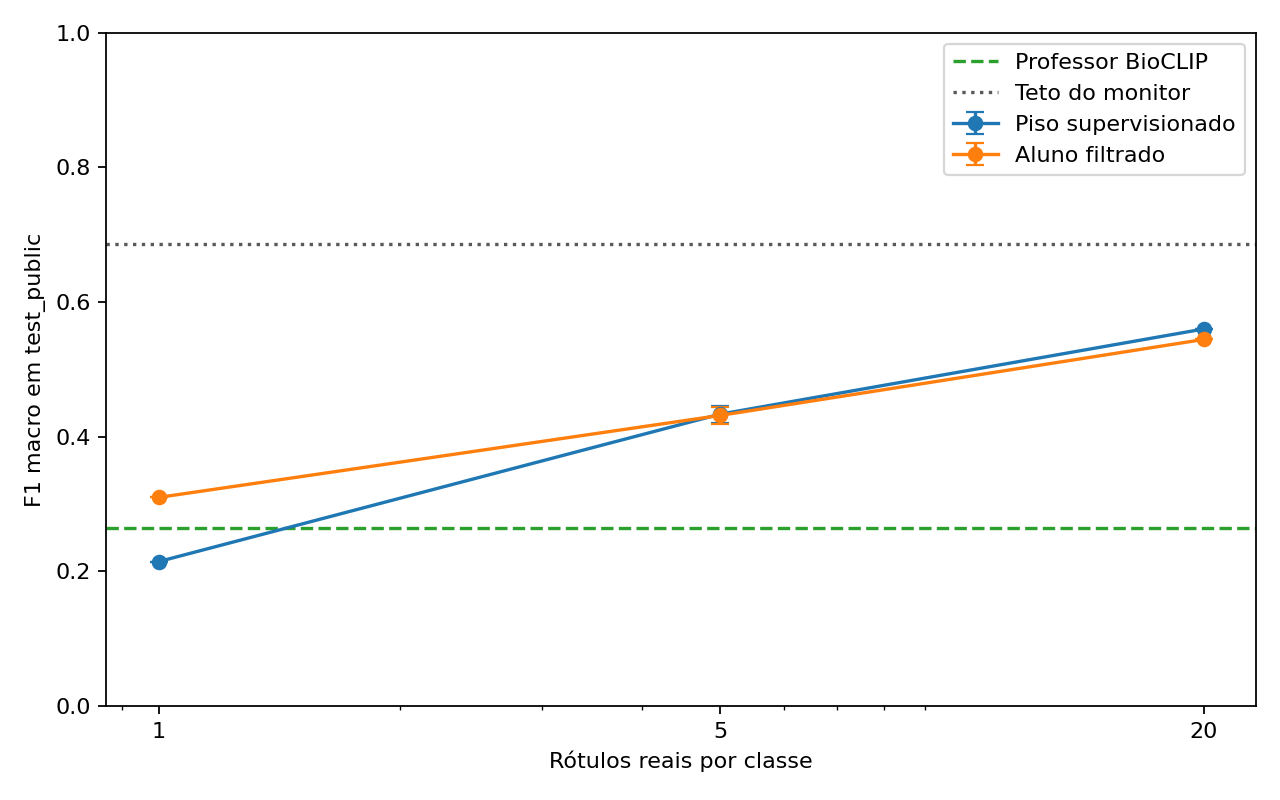

In [9]:
show_plot("curva_orcamento.png")

In [10]:
budget = pd.read_csv(OUTPUTS / "curva_orcamento.csv")
summary = budget.groupby(["orcamento", "metodo"], sort=True).agg(
    seeds=("seed", "count"),
    f1_medio=("f1_macro", "mean"),
    f1_desvio=("f1_macro", "std"),
    acuracia_media=("acuracia", "mean"),
    acuracia_desvio=("acuracia", "std"),
)
display(summary.rename(index={"baseline": "Piso", "student": "Aluno"}, level="metodo"))


seeds  f1_medio  f1_desvio  acuracia_media  acuracia_desvio
orcamento metodo                                                             
1         Piso        1    0.2144        NaN          0.2343              NaN
          Aluno       1    0.3098        NaN          0.3933              NaN
5         Piso        3    0.4335     0.0125          0.4743           0.0036
          Aluno       3    0.4316     0.0132          0.4809           0.0101
20        Piso        1    0.5600        NaN          0.5931              NaN
          Aluno       1    0.5445        NaN          0.5857              NaN

**O que dizer** — Com um rótulo por classe, o aluno ganha 9,54 pontos de F1 macro sobre o piso. Com cinco, as médias ficam próximas (piso 0,4335 e aluno 0,4316). Com vinte, o piso fica acima na seed testada (0,5600 e 0,5445). Os pseudo-rótulos tiveram seu maior benefício no menor orçamento.

### Ganhos e perdas por classe com orçamento 5

O ganho abaixo é a diferença entre as médias de F1 do aluno e do piso nas três seeds. A cor identifica o sinal da diferença.

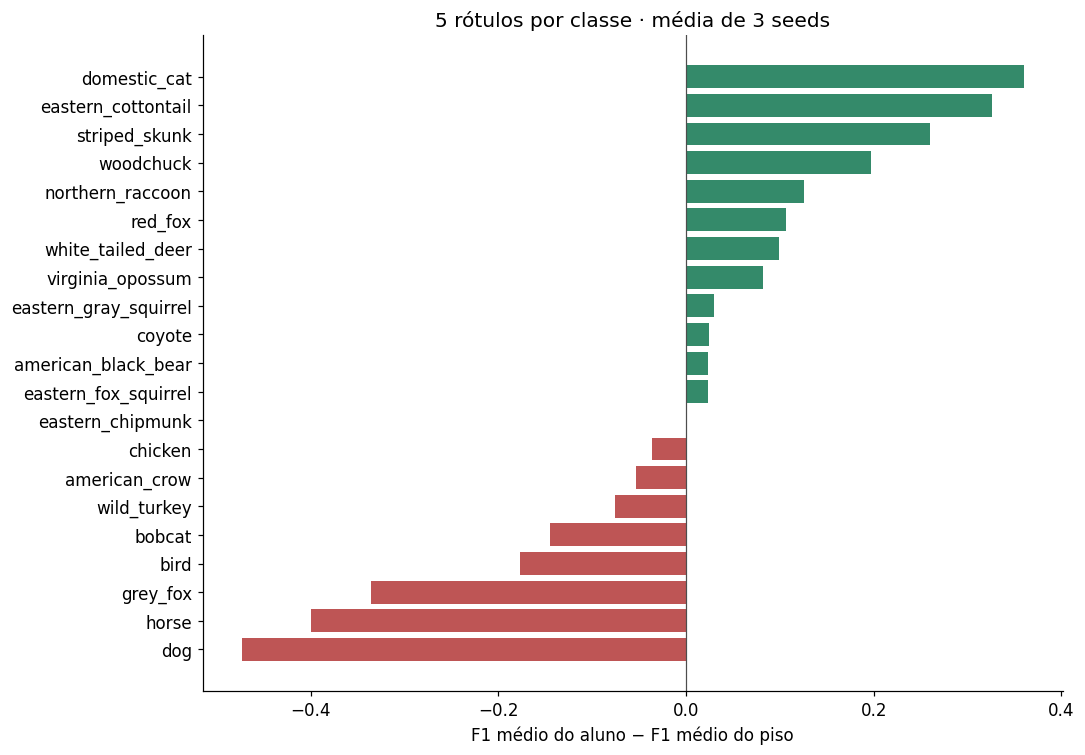

In [11]:
gains = pd.read_csv(OUTPUTS / "ganho_por_classe_5.csv").sort_values("ganho")
fig, ax = plt.subplots(figsize=(10, 7))
colors = ["#be5555" if value < 0 else "#348a6a" for value in gains["ganho"]]
ax.barh(gains["classe"], gains["ganho"], color=colors)
ax.axvline(0, color="0.3", linewidth=0.8)
ax.set(xlabel="F1 médio do aluno − F1 médio do piso", title="5 rótulos por classe · média de 3 seeds")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()


Destacar os ganhos de `domestic_cat`, `eastern_cottontail` e `striped_skunk`, e as perdas de `dog`, `horse` e `grey_fox`. `eastern_chipmunk` mantém o desempenho do piso. A média global próxima esconde mudanças grandes por classe. Cavalo tem apenas quatro imagens em test_public.

## Parte 3 · Para onde o aluno olhou?

As duas figuras abaixo carregam os mapas identificados como `checkpoint` nos nomes dos arquivos. Conferir qual checkpoint foi usado antes de atribuir esses exemplos ao modelo entregue. O mapa indica regiões que contribuíram para a classe prevista.

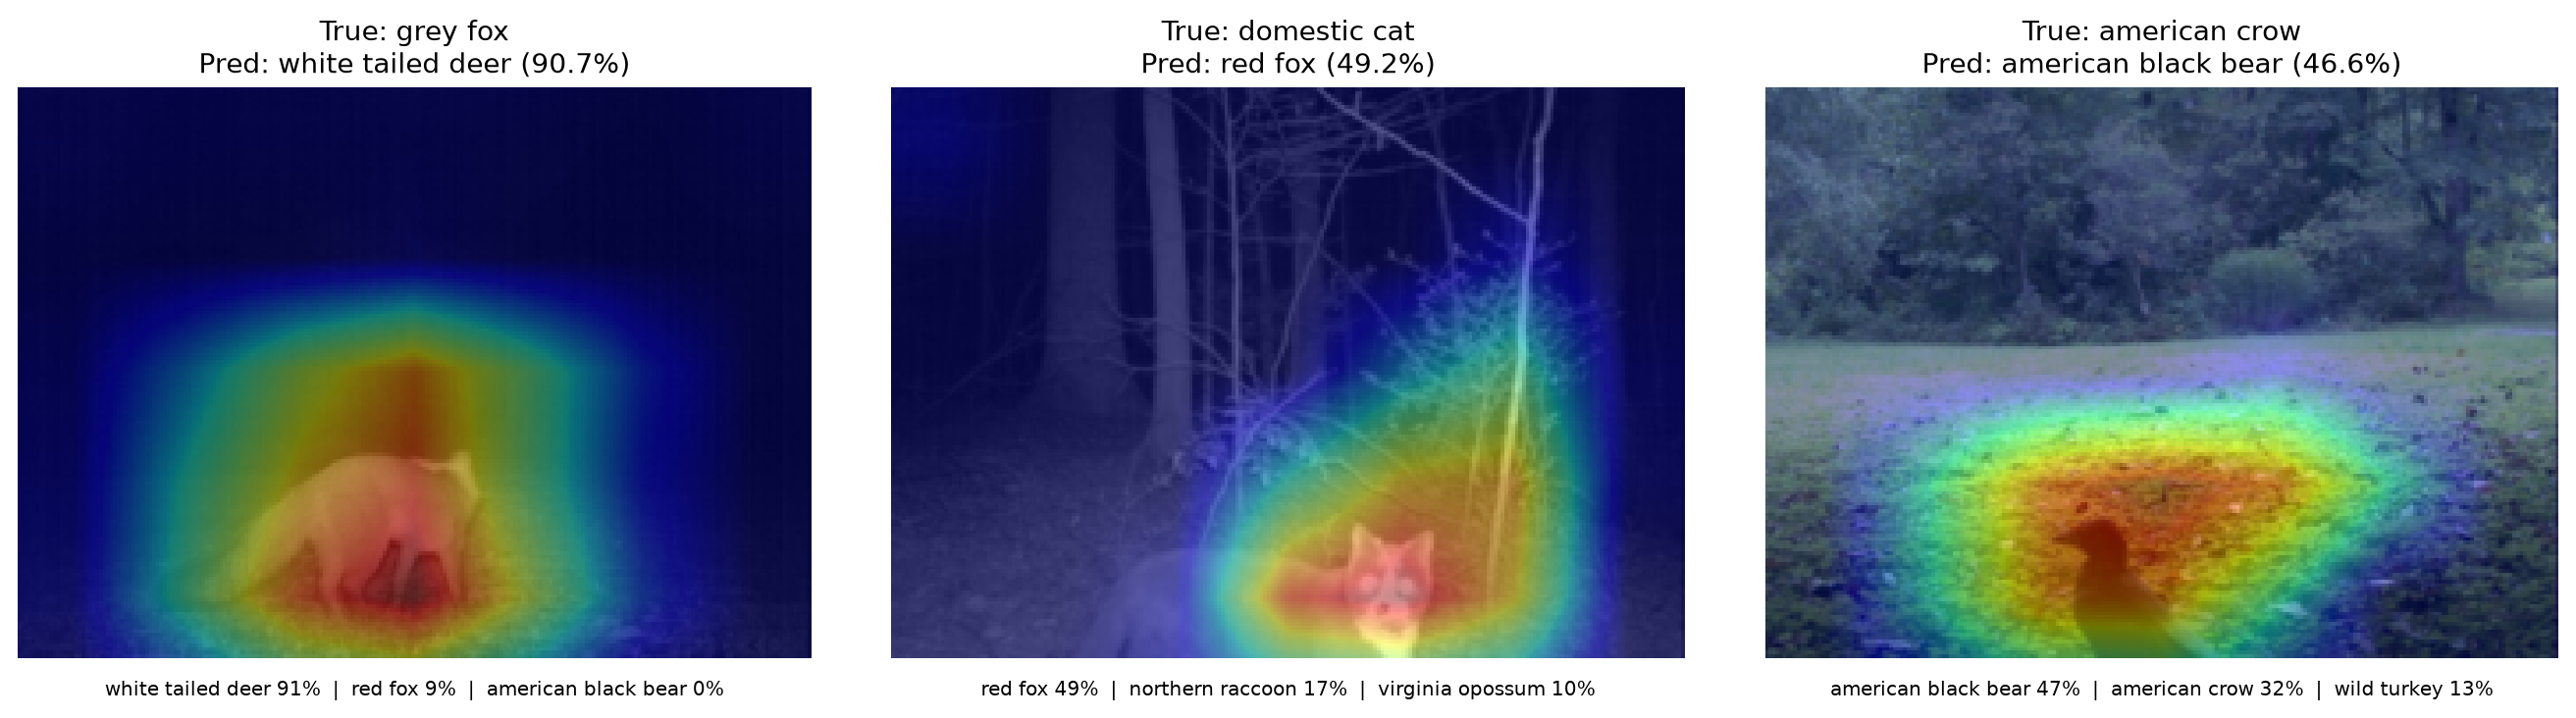

In [12]:
show_plot("student_specific_test_public_gradcam_checkpoint_3_examples.png", width=1200)

**Três erros** — A raposa cinzenta recebeu `white_tailed_deer` com 90,7%; o gato recebeu `red_fox` com 49,2%; o corvo recebeu `american_black_bear` com 46,6%. Nos três casos, há ativação próxima ao animal. Para discutir, observar a baixa informação visual e as regiões compartilhadas com o entorno, além da confiança alta no primeiro erro.

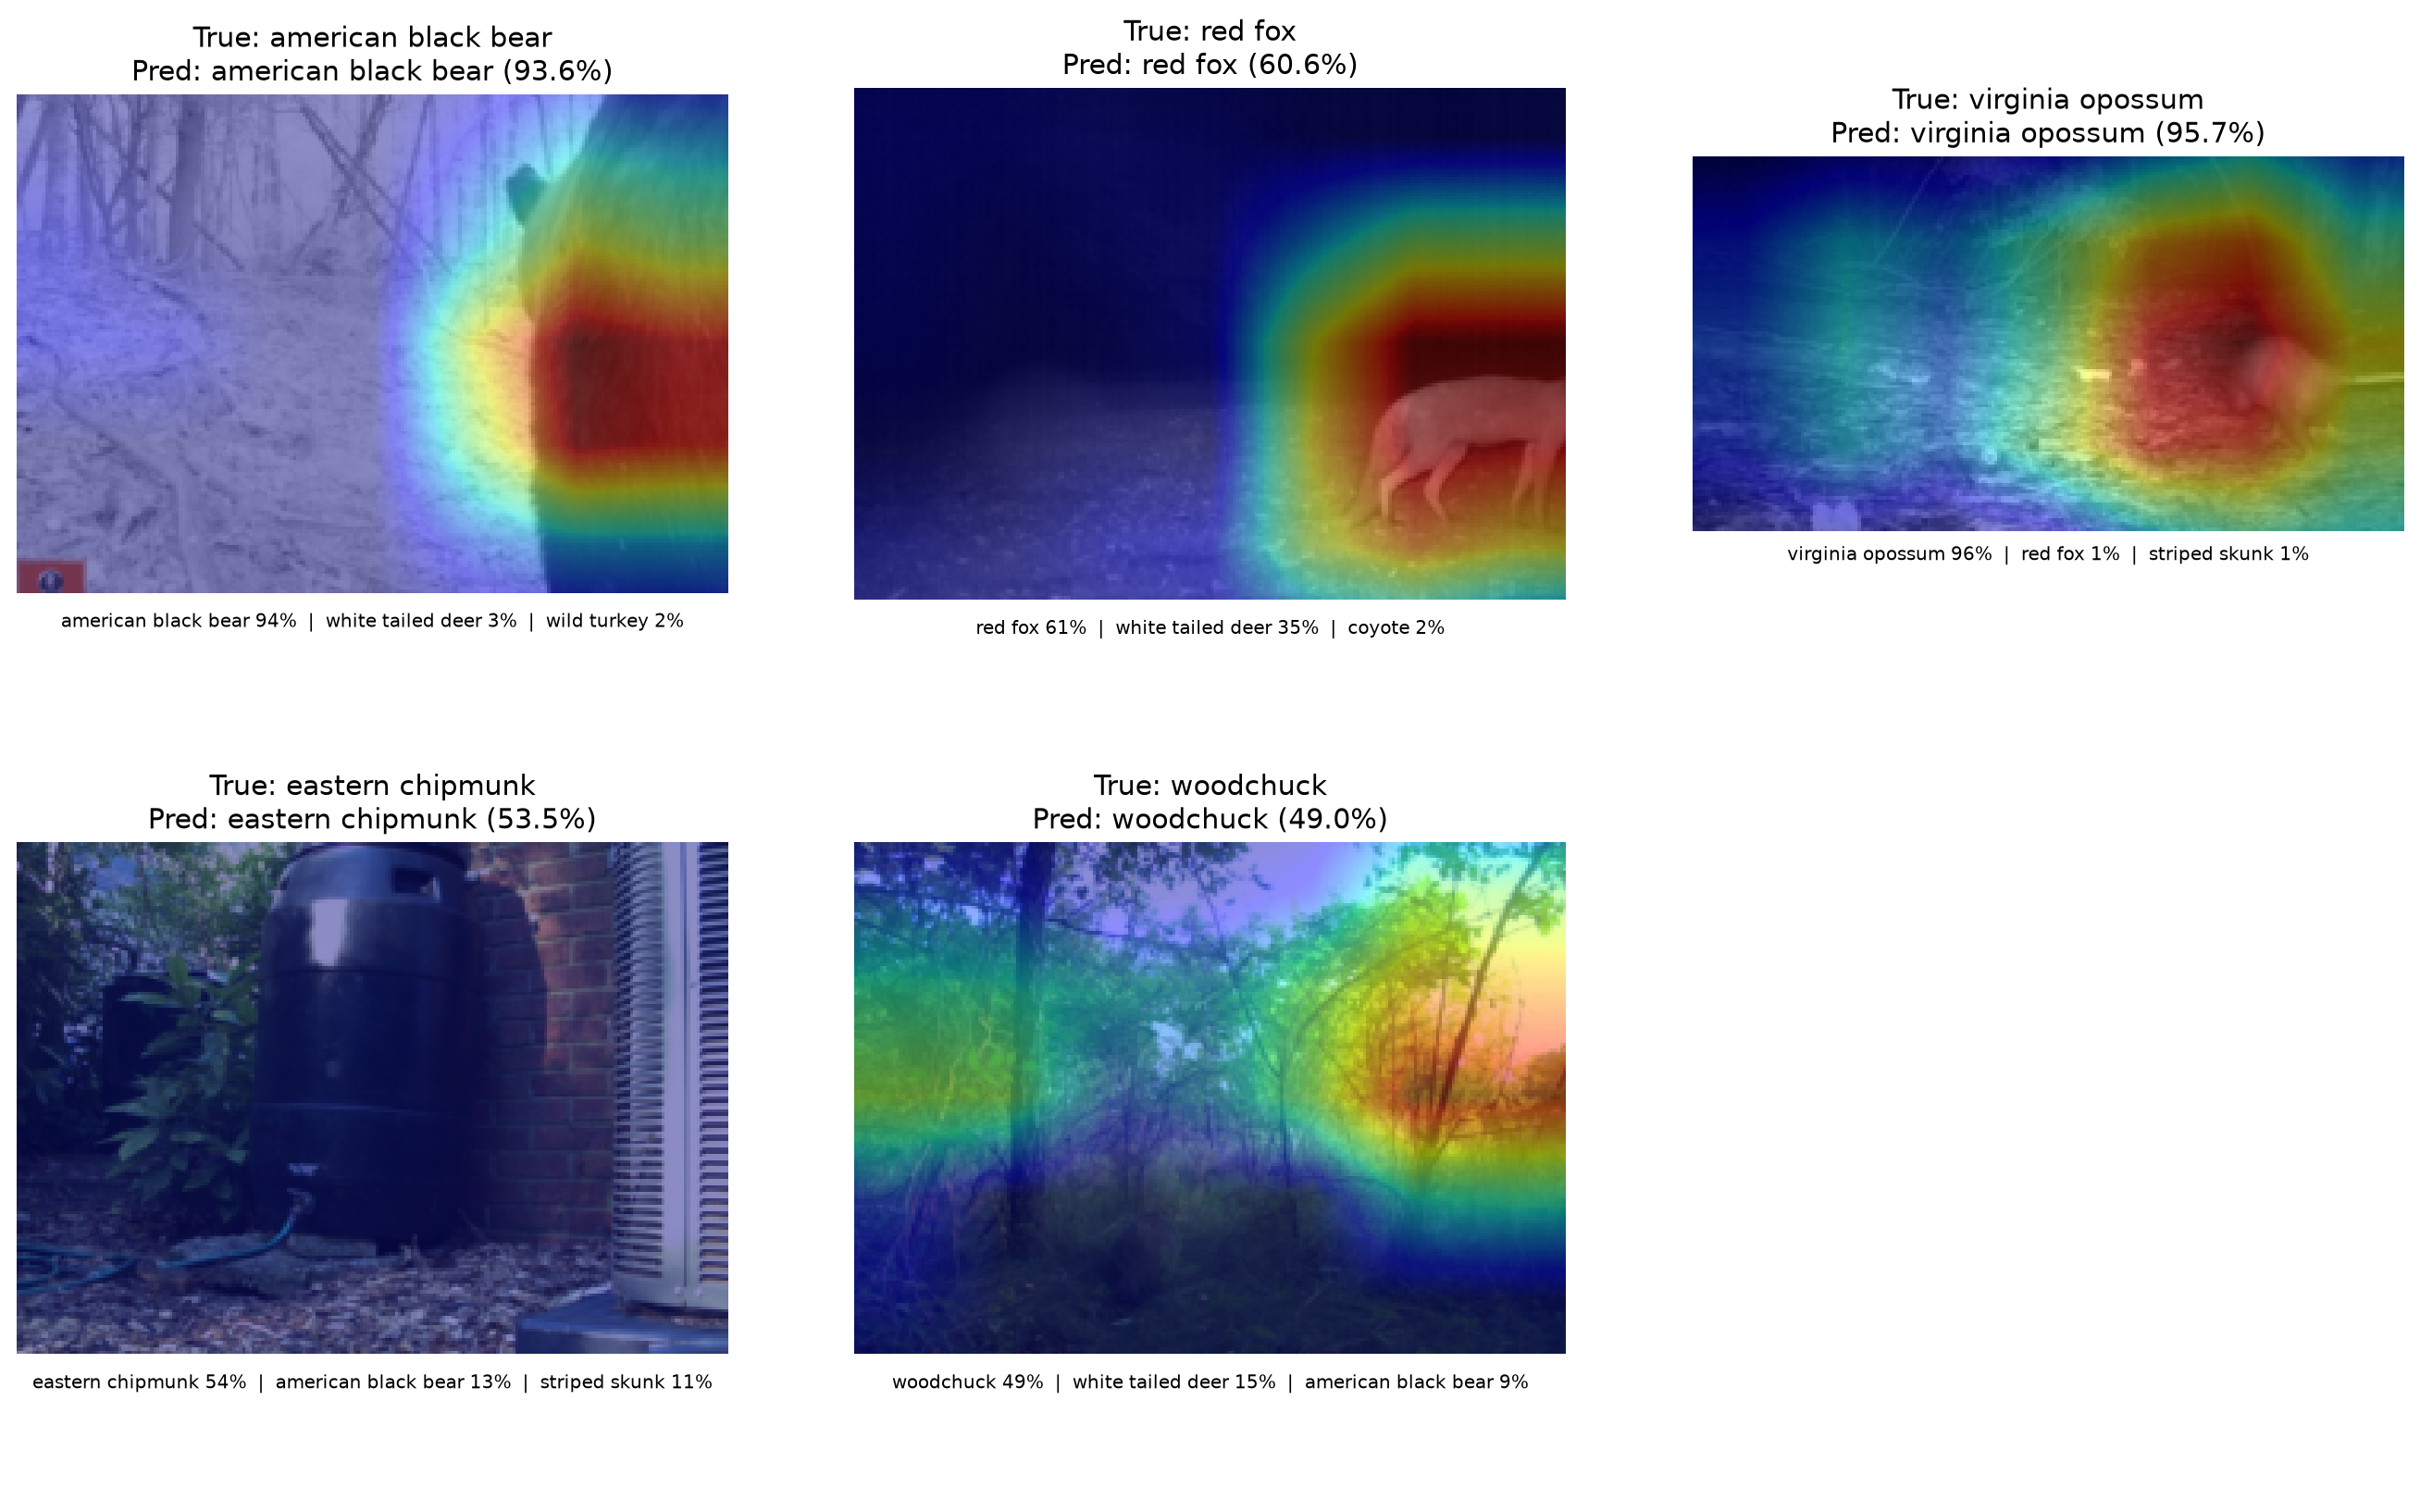

In [13]:
show_plot("student_specific_test_public_gradcam_checkpoint.png", width=1200)

**Cinco acertos** — Comparar a ativação no animal e no cenário. O exemplo de `woodchuck` mostra ativação forte em regiões da vegetação, o que merece discussão como possível atalho. Um mapa Grad-CAM é evidência visual para investigação; a atribuição causal ao fundo exigiria um teste adicional, como oclusão.

## Pergunta da capivara

Nosso aluno escolhe entre 21 classes conhecidas. Uma confiança máxima baixa poderia sinalizar uma imagem para revisão. Porém, ele também pode atribuir alta confiança a uma espécie desconhecida. A capacidade de rejeitar espécies fora das classes precisa de avaliação própria. O limiar usado para filtrar os pseudo-rótulos do professor foi escolhido para outra etapa do método.

## Conclusão para a apresentação

Os resultados mostram benefício maior dos pseudo-rótulos com um rótulo humano por classe. A filtragem melhora fortemente o aluno em relação à versão sem filtro. Com cinco rótulos, o F1 médio fica próximo ao do piso e os ganhos variam por classe. Os mapas de saliência ajudam a investigar se o aluno usa o animal e o cenário para acertar ou errar.